In [17]:
import numpy as np
import pandas as pd
import matplotlib as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [18]:
df=pd.read_csv(r"placementdata.csv")
df.head()

,StudentID,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,SSC_Marks,HSC_Marks,PlacementStatus
0,1,7.5,1,1,1,65,4.4,61,79,NotPlaced
1,2,8.9,0,3,2,90,4.0,78,82,Placed
2,3,7.3,1,2,2,82,4.8,79,80,NotPlaced
3,4,7.5,1,1,2,85,4.4,81,80,Placed
4,5,8.3,1,2,2,86,4.5,74,88,Placed


In [19]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   StudentID                 10000 non-null  int64  
 1   CGPA                      10000 non-null  float64
 2   Internships               10000 non-null  int64  
 3   Projects                  10000 non-null  int64  
 4   Workshops/Certifications  10000 non-null  int64  
 5   AptitudeTestScore         10000 non-null  int64  
 6   SoftSkillsRating          10000 non-null  float64
 7   SSC_Marks                 10000 non-null  int64  
 8   HSC_Marks                 10000 non-null  int64  
 9   PlacementStatus           10000 non-null  str    
dtypes: float64(2), int64(7), str(1)
memory usage: 857.0 KB


In [20]:
df.isnull().sum()

StudentID                   0
CGPA                        0
Internships                 0
Projects                    0
Workshops/Certifications    0
AptitudeTestScore           0
SoftSkillsRating            0
SSC_Marks                   0
HSC_Marks                   0
PlacementStatus             0
dtype: int64

In [5]:
df.shape

(10000, 10)

In [6]:
# data split(x,y)
x=df.iloc[:,1:-1]
y=df.iloc[:,-1]
print(x.columns)
print(y)

Index(['CGPA', 'Internships', 'Projects', 'Workshops/Certifications',
       'AptitudeTestScore', 'SoftSkillsRating', 'SSC_Marks', 'HSC_Marks'],
      dtype='str')
0       NotPlaced
1          Placed
2       NotPlaced
3          Placed
4          Placed
          ...    
9995    NotPlaced
9996       Placed
9997       Placed
9998       Placed
9999    NotPlaced
Name: PlacementStatus, Length: 10000, dtype: str


In [7]:
y.value_counts()

PlacementStatus
NotPlaced    5803
Placed       4197
Name: count, dtype: int64

In [8]:
from sklearn.preprocessing import LabelEncoder
# /initialize labelencoder  //fit and transform the data to numeric labeles
y=LabelEncoder().fit_transform(y)
y

array([0, 1, 0, ..., 1, 1, 0], shape=(10000,))

In [9]:
from imblearn.under_sampling import RandomUnderSampler
from collections import Counter
# apply undersampling
rus=RandomUnderSampler()
X,Y=rus.fit_resample(x,y)

print(Counter(Y))

Counter({np.int64(0): 4197, np.int64(1): 4197})


In [10]:
from imblearn.over_sampling import RandomOverSampler
from collections import Counter
# apply oversampling
rus=RandomOverSampler()
X1,Y1=rus.fit_resample(x,y)

print(Counter(Y1))

Counter({np.int64(0): 5803, np.int64(1): 5803})


In [21]:
from sklearn.model_selection import train_test_split

In [22]:
# splitting data into traning and testing sets
x_train,x_test,y_train,y_test=train_test_split(X1,Y1,test_size=0.2,random_state=20)

In [23]:
x_train.shape

(9284, 8)

In [24]:
x_test.shape

(2322, 8)

In [25]:
from sklearn.linear_model import LogisticRegression
# creating and training the logistic regression model
log_model=LogisticRegression().fit(x_train,y_train)

In [26]:
# get predicted probabilities for the positive class
y_pred=log_model.predict(x_test)
y_pred

array([1, 0, 0, ..., 1, 1, 1], shape=(2322,))

In [27]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
# evaluating the model
cm=confusion_matrix(y_test,y_pred)

print(cm)

[[875 304]
 [277 866]]


In [28]:
report =classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.76      0.74      0.75      1179
           1       0.74      0.76      0.75      1143

    accuracy                           0.75      2322
   macro avg       0.75      0.75      0.75      2322
weighted avg       0.75      0.75      0.75      2322



In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

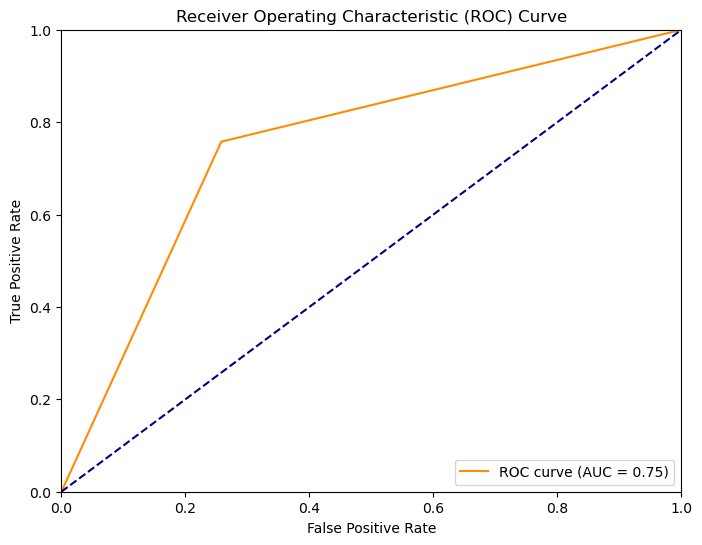

In [30]:
from sklearn.metrics import roc_curve, auc

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred)

# Compute AUC (Area Under the Curve)
roc_auc = auc(fpr, tpr)

# Plotting the ROC curve
plt.figure(figsize=(8, 6))
#plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot(fpr, tpr, color='darkorange', label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()